## Demo 1: Finding structure in a synthetic neuron

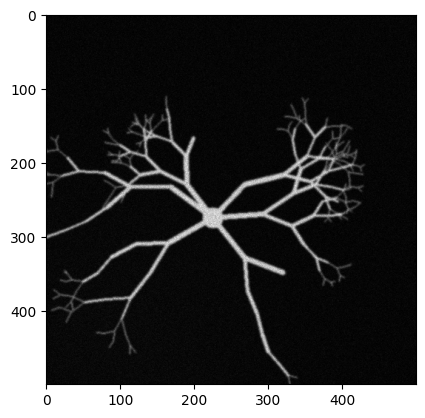

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage

# Load in the synthetic neuron image
neuron_img = cv2.imread("neuron_image.png", cv2.IMREAD_GRAYSCALE)

plt.imshow(neuron_img, cmap='gray')
plt.show()

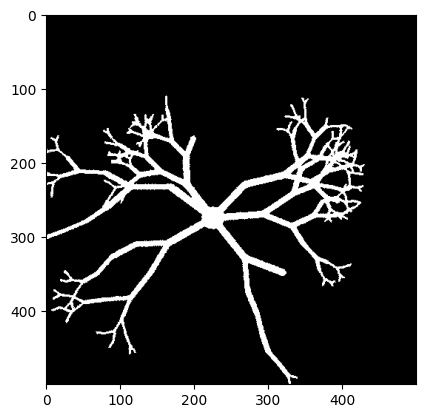

In [29]:
# Process thresholding with Otsu's method
ret, thresh = cv2.threshold(neuron_img, 30, 255, cv2.THRESH_BINARY)

plt.imshow(thresh, cmap='gray')
plt.show()

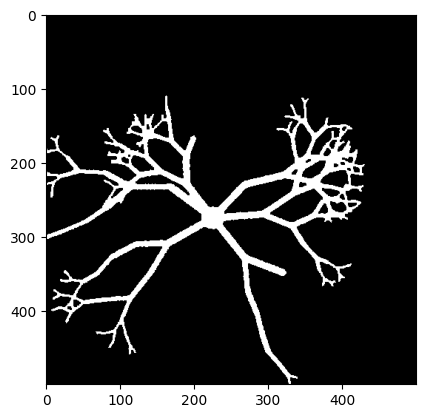

In [33]:
# Clean up mask with morphological operations
kernel = np.ones((3,3), np.uint8)
morph = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)
plt.imshow(morph, cmap='gray')
plt.show()

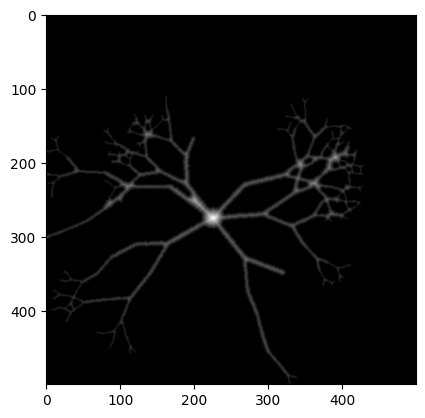

In [34]:
# Compute the distance transform
dist = cv2.distanceTransform(morph, cv2.DIST_L2, 3)
plt.imshow(dist, cmap='gray')
plt.show()

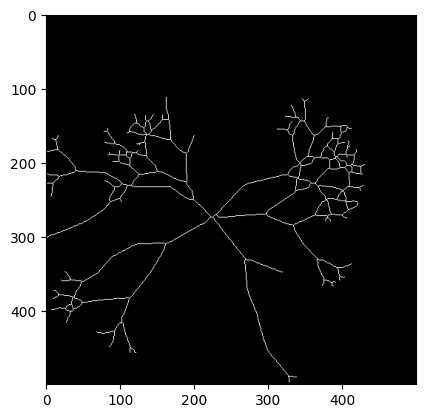

In [36]:
# Compute the skeleton
skeleton = skimage.morphology.skeletonize(morph.astype(bool))
plt.imshow(skeleton, cmap='gray')
plt.show()

In [47]:
#!pip install skan
import skan

# Analyze the graph made by the skeleton
skeleton_obj = skan.Skeleton(skeleton)
branch_data = skan.summarize(skeleton_obj)

print(f"Number of branches: {branch_data.shape[0]}")
print(f"Total length of all branches: {branch_data['branch-distance'].sum()}")

Number of branches: 230
Total length of all branches: 4253.703027829439


/var/folders/1h/phzg991d7bn15bphmc87wt680000gp/T/ipykernel_78389/3066990861.py:6: VisibleDeprecationWarning: separator in column name will change to _ in version 0.13; to silence this warning, use `separator='-'` to maintain current behavior and use `separator='_'` to switch to the new default behavior.
  branch_data = skan.summarize(skeleton_obj)


## Demo 2: Real Measurments for an Eye Fundus Image

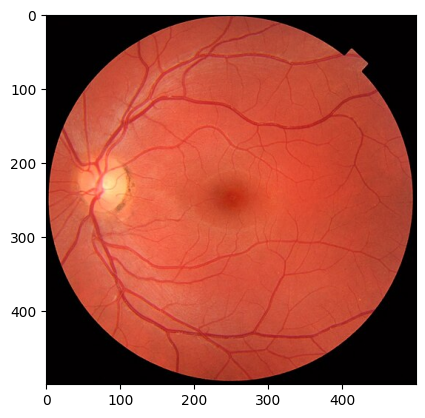

In [52]:
# Load the image and convert to RGB
eye_image = cv2.imread('eye.jpg', cv2.IMREAD_COLOR)
eye_image = cv2.cvtColor(eye_image, cv2.COLOR_RGB2BGR)

plt.imshow(eye_image)
plt.show()

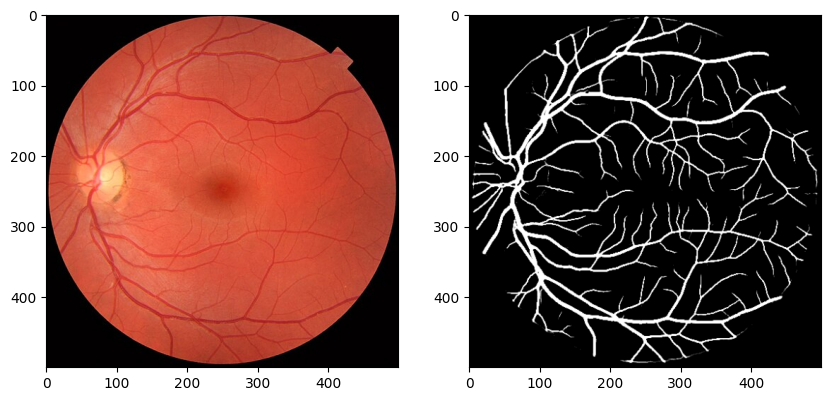

In [ ]:
# Use an advanced eye segmentation technique
#!pip install fundus_image_toolbox
import fundus_image_toolbox as fit
ensemble = fit.load_segmentation_ensemble(device="cpu")
vessel_mask = fit.ensemble_predict_segmentation(ensemble, [eye_image], threshold=0.5, size=(512, 512))
fit.plot_masks([eye_image], vessel_mask)

In [70]:
import skan

# Analyze the graph made by the skeleton
skeleton_obj = skan.Skeleton(skeleton)
branch_data = skan.summarize(skeleton_obj)

print(f"Number of branches: {branch_data.shape[0]}")
print(f"Total length of all branches: {branch_data['branch-distance'].sum()}")
print(f"Average length of each branch: {branch_data['branch-distance'].mean()}")

branch_data['tortuosity'] = (
    branch_data['branch-distance'] / branch_data['euclidean-distance']
)
print(f"Average tortuosity: {branch_data['tortuosity'].mean()}")
print(f"Median tortuosity: {branch_data['tortuosity'].median()}")


Number of branches: 511
Total length of all branches: 10505.218464330199
Average length of each branch: 20.558157464442658
Average tortuosity: 1.0815360617817018
Median tortuosity: 1.07248911335735


/var/folders/1h/phzg991d7bn15bphmc87wt680000gp/T/ipykernel_78389/3664807352.py:5: VisibleDeprecationWarning: separator in column name will change to _ in version 0.13; to silence this warning, use `separator='-'` to maintain current behavior and use `separator='_'` to switch to the new default behavior.
  branch_data = skan.summarize(skeleton_obj)
